In [ ]:
import torch
from PIL import Image
from diffusers import QwenImageEditPlusPipeline

In [ ]:
pipeline = QwenImageEditPlusPipeline.from_pretrained(
    "Qwen/Qwen-Image-Edit-2509", torch_dtype=torch.bfloat16, device_map="balanced"
)

In [8]:
prompt = """提供的图片是主题为‘中华民族一家亲’的手抄报，图片需要做一些调整：
将画面底部中央的5个人物缩小，5个高度基本一致，中间的人物稍高，两侧的稍矮
不超过画面高度的1/4，背景保持不变，继续突出‘中华民族一家亲’的主题。"""

In [9]:
pipeline.set_progress_bar_config(disable=None)
image1 = Image.open(r"../1111.png").convert("RGB")
# image2 = Image.open("../temp/mm2.png")
# image3 = Image.open("../temp/sample03.jpg")

inputs = {
    "image": image1,
    "prompt": prompt,
    "true_cfg_scale": 4.0,
    "negative_prompt": "",
    "num_inference_steps": 50,
    # "guidance_scale": 1.0,
    "num_images_per_prompt": 3,
}


  0%|          | 0/50 [00:00<?, ?it/s]

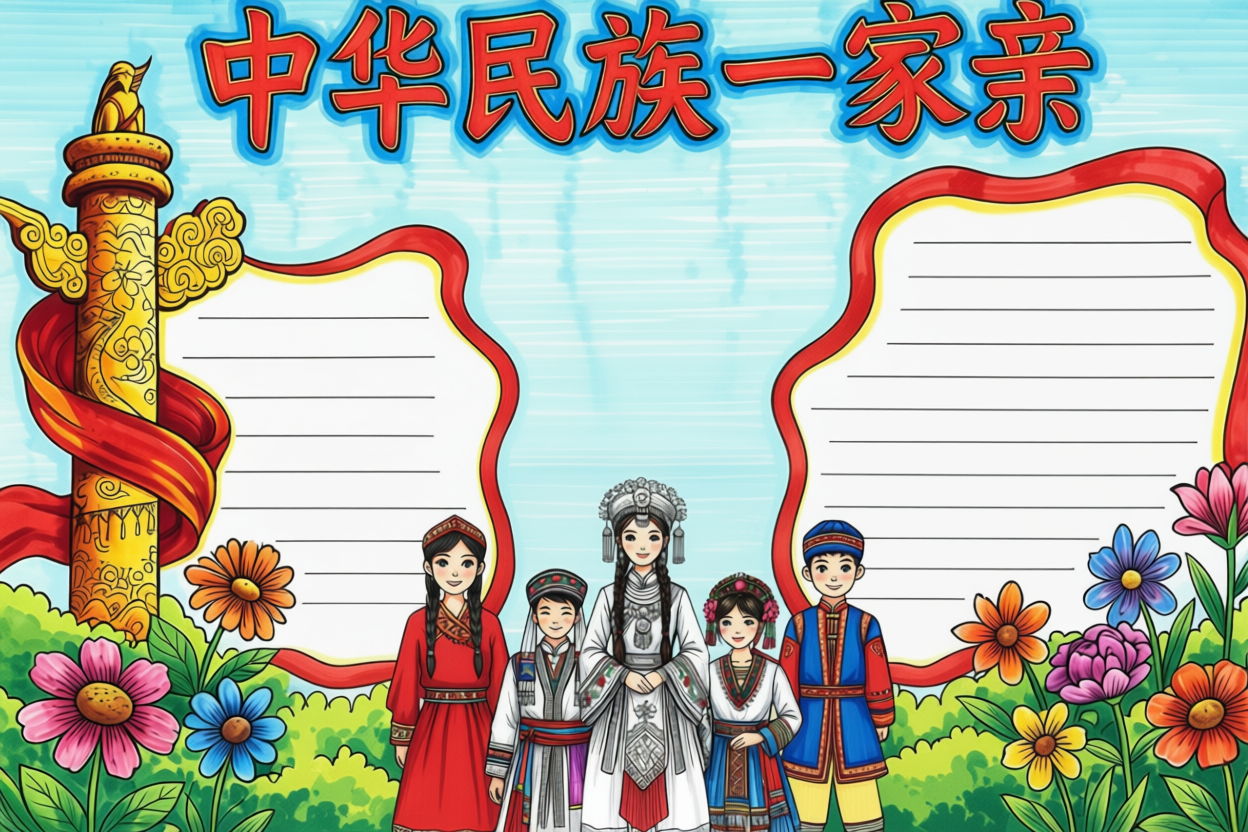

In [10]:
with torch.inference_mode():
    output = pipeline(**inputs)
    output_images = output.images

output_images[0]

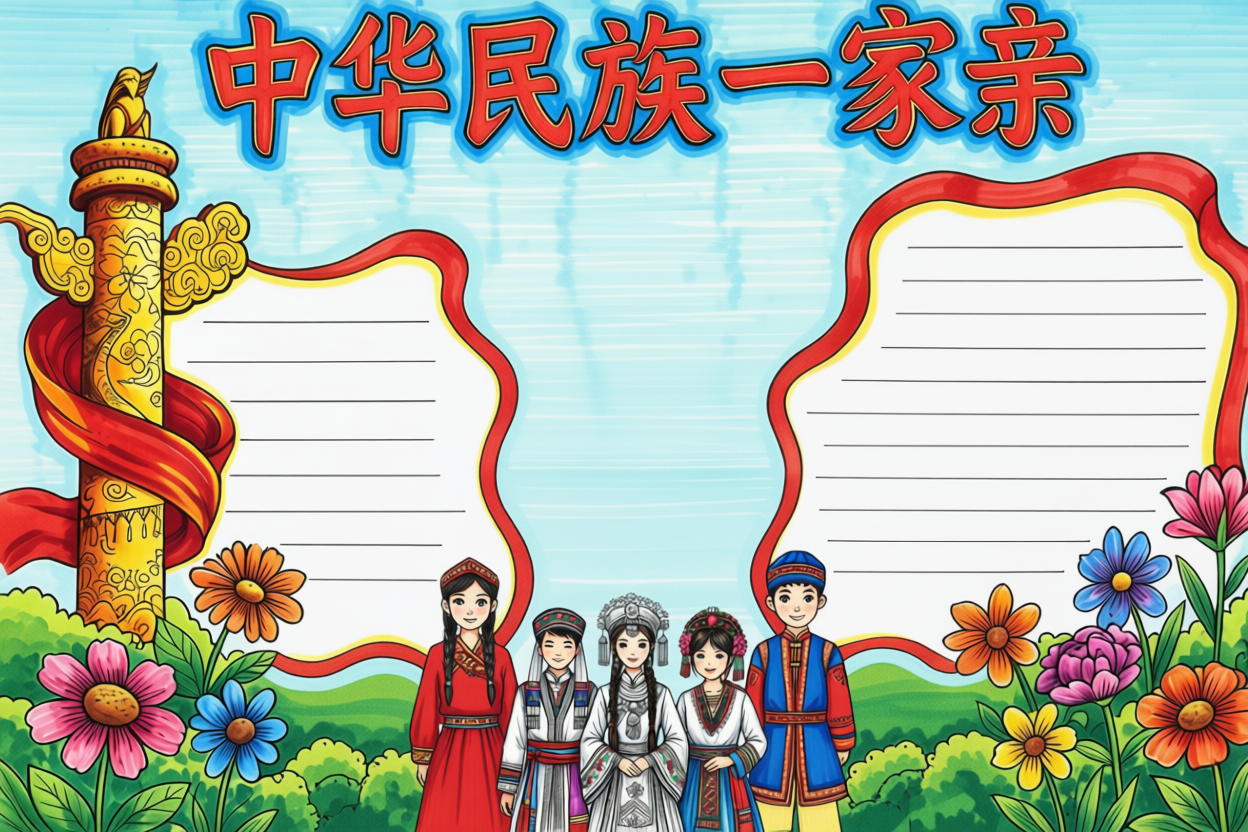

In [11]:
output_images[1]

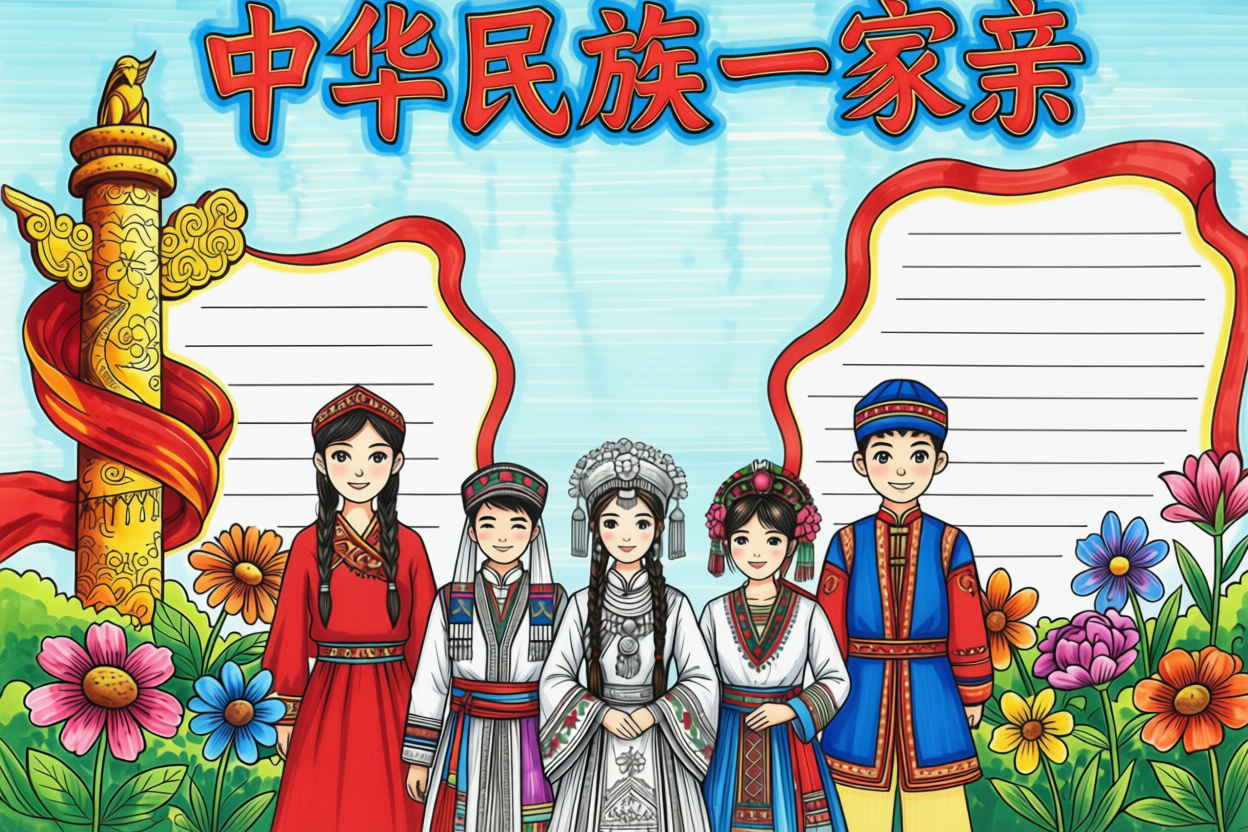

In [12]:
output_images[2]
